In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image


In [2]:
DATA_DIR = Path("/pscratch/sd/e/elavarpa/sam3_vid_data")

print("Folders:")
for d in DATA_DIR.iterdir():
    if d.is_dir():
        print(" -", d.name)


Folders:
 - cortex
 - outer_cells
 - Xylem_vessels
 - Phloem_Fibers
 - Pith_cells


Total slices: 2160
Using slice: 20211222_125057_petiole4_02000_mask.tif
Image: (2560, 2560, 3)
Loaded: ['cortex', 'Phloem_Fibers', 'Xylem_vessels', 'Pith_cells', 'outer_cells']


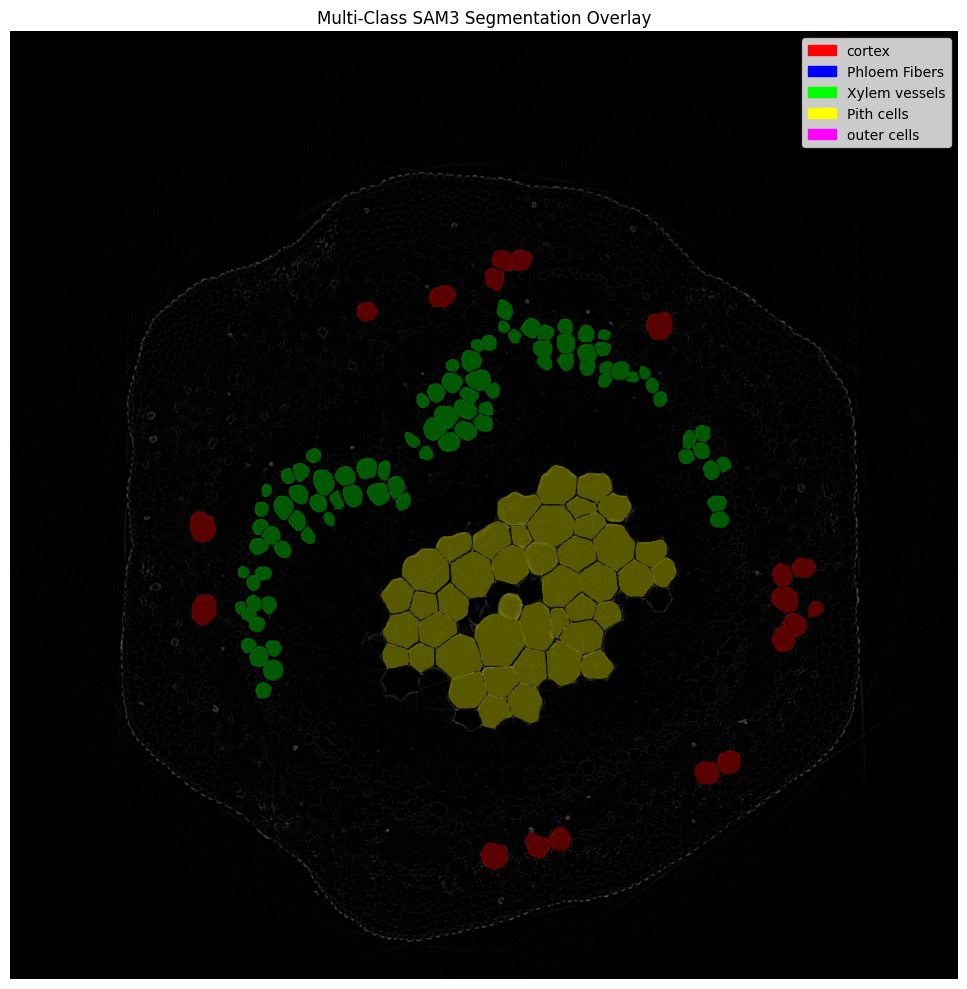

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import matplotlib.patches as mpatches


# =========================
# Paths
# =========================

DATA_DIR = Path("/pscratch/sd/e/elavarpa/sam3_vid_data")
IMG_DIR  = Path("/global/cfs/cdirs/als/synaps/rec20211222_125057_petiole4")


# =========================
# Class colors (RGB)
# =========================

CLASSES = {
    "cortex":        (1.0, 0.0, 0.0),   # Red
    "Phloem_Fibers": (0.0, 0.0, 1.0),   # Blue
    "Xylem_vessels": (0.0, 1.0, 0.0),   # Green
    "Pith_cells":    (1.0, 1.0, 0.0),   # Yellow
    "outer_cells":   (1.0, 0.0, 1.0),   # Magenta
}


# =========================
# Pick slice index
# =========================

IDX = 2000   # change if needed


# =========================
# Get reference mask
# =========================

ref_dir = DATA_DIR / list(CLASSES.keys())[0]

files = sorted(
    list(ref_dir.glob("*.tif")) +
    list(ref_dir.glob("*.tiff"))
)

print("Total slices:", len(files))

mask_path = files[IDX]

print("Using slice:", mask_path.name)


# =========================
# Base name
# =========================

base = mask_path.stem.replace("_mask", "")


# =========================
# Load original image
# =========================

candidates = [
    IMG_DIR / f"{base}.tif",
    IMG_DIR / f"{base}.tiff",
]

img_path = None

for c in candidates:
    if c.exists():
        img_path = c
        break

if img_path is None:
    raise FileNotFoundError(base)

img = np.array(Image.open(img_path).convert("RGB"))

print("Image:", img.shape)


# =========================
# Load all masks
# =========================

all_masks = {}

for cls in CLASSES:

    cls_dir = DATA_DIR / cls

    candidates = [
        cls_dir / f"{base}_mask.tif",
        cls_dir / f"{base}_mask.tiff",
    ]

    mask_path = None

    for c in candidates:
        if c.exists():
            mask_path = c
            break

    if mask_path is None:
        print(f"⚠ Missing {cls}")
        continue

    mask = np.array(Image.open(mask_path)).astype(np.float32)

    if mask.max() > 1:
        mask /= 255.0

    all_masks[cls] = mask


print("Loaded:", list(all_masks.keys()))


# =========================
# Build RGBA overlay
# =========================

H, W = img.shape[:2]

overlay = np.zeros((H, W, 4), dtype=np.float32)

ALPHA = 0.35


for cls, color in CLASSES.items():

    if cls not in all_masks:
        continue

    mask = all_masks[cls] > 0.5

    r, g, b = color

    overlay[mask, 0] = r
    overlay[mask, 1] = g
    overlay[mask, 2] = b
    overlay[mask, 3] = ALPHA


# =========================
# Plot
# =========================

plt.figure(figsize=(10,10))

plt.imshow(img)
plt.imshow(overlay)

# Legend
handles = []

for cls, color in CLASSES.items():
    if cls in all_masks:
        handles.append(
            mpatches.Patch(
                color=color,
                label=cls.replace("_", " ")
            )
        )

plt.legend(handles=handles, loc="upper right")

plt.title("Multi-Class SAM3 Segmentation Overlay")
plt.axis("off")
plt.tight_layout()
plt.show()
